<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">WNBA Opening &amp; Closing Odds — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">The figures of the listing and of its README, recomputed from the file of the
full product: 2,034 WNBA games from 18 May 2018 to 29 July 2026, the opening line and the closing prices of seven
sportsbooks on the moneyline, the spread and the total, with the public betting split on each market.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing or of the
README, recomputes it from the file and prints **PASS** or **FAIL**. The expected values are written once, in plain
sight, in the `CLAIMS` cell; everything else is read from the data. Only the counts of prices left out while the file
was built (212 markets, listed rule by rule in the README) cannot be recomputed: those prices are, by
definition, not in the file.

🏀 **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/rnlhra?utm_source=github&utm_medium=notebook&utm_campaign=wnba_oc&utm_content=notebook_top)** · also on [Whop](https://whop.com/oliviersportsdata/wnba-opening-closing-odds-7-books-opening-line-2018-2026/?utm_source=github&utm_medium=notebook&utm_campaign=wnba_oc&utm_content=whop_top) · free 20-game sample: same layout, same 137 columns.

## 0 · Setup

In [1]:
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

def find_csv():
    """The CSV of the full product: the largest WNBA_Opening_Closing_Odds file wins (sample and full may both be attached)."""
    hits = []
    for base in (os.environ.get("WNBA_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += [p for p in glob.glob(os.path.join(base, "**", "WNBA_Opening_Closing_Odds_2018-2026*.csv"), recursive=True)
                     if os.path.isfile(p)]
    if not hits:
        raise FileNotFoundError("WNBA_Opening_Closing_Odds_2018-2026.csv not found: attach the dataset to this notebook")
    return max(hits, key=os.path.getsize)

PATH = find_csv()
BYTES = open(PATH, "rb").read()
S = pd.read_csv(PATH, sep=";", encoding="utf-8-sig", dtype=str, keep_default_na=False)   # every cell as written
F = pd.read_csv(PATH, sep=";", encoding="utf-8-sig")                                      # the same file, numbers parsed
print(f"{os.path.basename(PATH)}  ·  {len(BYTES) / 1e6:.2f} MB  ·  {len(F):,} rows  ·  {F.shape[1]} columns")

SOURCES = ["Opener", "Betcris", "Heritage", "BetOnline", "Bovada", "BetAnything", "WilliamHill", "Everygame"]
BOOKS = SOURCES[1:]                                # the seven sportsbooks, closing prices; Opener = the opening line
NAME = {"WilliamHill": "William Hill", "Opener": "Opening line"}
MARKETS = {"ML": ["ML_Away_US", "ML_Away_Dec", "ML_Home_US", "ML_Home_Dec"],
           "Spread": ["Spread_Away_Line", "Spread_Away_US", "Spread_Away_Dec", "Spread_Home_Line", "Spread_Home_US", "Spread_Home_Dec"],
           "Total": ["Total_Line", "Total_Over_US", "Total_Over_Dec", "Total_Under_US", "Total_Under_Dec"]}
PAIRS = {"ML": ("ML_Away_US", "ML_Home_US"), "Spread": ("Spread_Away_US", "Spread_Home_US"), "Total": ("Total_Over_US", "Total_Under_US")}
KEY = {"ML": "ML_Away_US", "Spread": "Spread_Away_Line", "Total": "Total_Line"}
US_COLS = [c for c in F.columns if c.endswith("_US")]

def imp(us):
    """Implied probability of an American price."""
    us = np.asarray(us, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(us < 0, -us / (100 - us), 100 / (us + 100))

def no_vig(home, away):
    """Implied probability of the home team, margin removed proportionally."""
    h, a = imp(home), imp(away)
    return h / (h + a)

RESULTS = []
def check(claim, ok, detail=""):
    ok = bool(ok)
    RESULTS.append((claim, ok, detail))
    print(f"{'PASS' if ok else 'FAIL'}  {claim}" + (f"   [{detail}]" if detail else ""))

# Olivier Sports Data dark signature
BG, FG, FG2, GRID, CYAN, AMBER = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff", "#e3a008"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": FG,
                     "axes.labelcolor": FG, "axes.edgecolor": GRID, "xtick.color": FG2, "ytick.color": FG2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.titlecolor": FG,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10, "legend.frameon": False})

WNBA_Opening_Closing_Odds_2018-2026.csv  ·  1.29 MB  ·  2,034 rows  ·  137 columns


## 1 · The claims

Copied from the listing, the README shipped in the ZIP and the images of the listing. Nothing below is adjusted to
fit: if the file disagrees, the cell prints FAIL.

In [2]:
CLAIMS = {
 "games": 2034,
 "columns": 137,
 "first_date": "2018-05-18",
 "last_date": "2026-07-29",
 "games_per_season": {
  "2018": 215,
  "2019": 220,
  "2020": 138,
  "2021": 210,
  "2022": 240,
  "2023": 261,
  "2024": 263,
  "2025": 278,
  "2026": 209
 },
 "prices": 89964,
 "teams": [
  "Atlanta Dream",
  "Chicago Sky",
  "Connecticut Sun",
  "Dallas Wings",
  "Golden State Valkyries",
  "Indiana Fever",
  "Las Vegas Aces",
  "Los Angeles Sparks",
  "Minnesota Lynx",
  "New York Liberty",
  "Phoenix Mercury",
  "Portland Fire",
  "Seattle Storm",
  "Toronto Tempo",
  "Washington Mystics"
 ],
 "games_per_team_complete_seasons": {
  "2019": {
   "Atlanta Dream": 34,
   "Chicago Sky": 36,
   "Connecticut Sun": 42,
   "Dallas Wings": 34,
   "Indiana Fever": 34,
   "Las Vegas Aces": 39,
   "Los Angeles Sparks": 38,
   "Minnesota Lynx": 35,
   "New York Liberty": 34,
   "Phoenix Mercury": 35,
   "Seattle Storm": 36,
   "Washington Mystics": 43
  },
  "2021": {
   "Atlanta Dream": 32,
   "Chicago Sky": 42,
   "Connecticut Sun": 37,
   "Dallas Wings": 33,
   "Indiana Fever": 32,
   "Las Vegas Aces": 37,
   "Los Angeles Sparks": 32,
   "Minnesota Lynx": 33,
   "New York Liberty": 33,
   "Phoenix Mercury": 43,
   "Seattle Storm": 34,
   "Washington Mystics": 32
  },
  "2022": {
   "Atlanta Dream": 36,
   "Chicago Sky": 45,
   "Connecticut Sun": 48,
   "Dallas Wings": 39,
   "Indiana Fever": 36,
   "Las Vegas Aces": 47,
   "Los Angeles Sparks": 36,
   "Minnesota Lynx": 36,
   "New York Liberty": 39,
   "Phoenix Mercury": 38,
   "Seattle Storm": 42,
   "Washington Mystics": 38
  },
  "2023": {
   "Atlanta Dream": 42,
   "Chicago Sky": 42,
   "Connecticut Sun": 47,
   "Dallas Wings": 45,
   "Indiana Fever": 40,
   "Las Vegas Aces": 50,
   "Los Angeles Sparks": 40,
   "Minnesota Lynx": 43,
   "New York Liberty": 51,
   "Phoenix Mercury": 40,
   "Seattle Storm": 40,
   "Washington Mystics": 42
  },
  "2024": {
   "Atlanta Dream": 42,
   "Chicago Sky": 40,
   "Connecticut Sun": 47,
   "Dallas Wings": 40,
   "Indiana Fever": 42,
   "Las Vegas Aces": 46,
   "Los Angeles Sparks": 40,
   "Minnesota Lynx": 53,
   "New York Liberty": 52,
   "Phoenix Mercury": 42,
   "Seattle Storm": 42,
   "Washington Mystics": 40
  }
 },
 "coverage_games": {
  "Opener": {
   "ML": 1970,
   "Spread": 1991,
   "Total": 2025
  },
  "Betcris": {
   "ML": 1658,
   "Spread": 1707,
   "Total": 1709
  },
  "Heritage": {
   "ML": 2020,
   "Spread": 2019,
   "Total": 1962
  },
  "BetOnline": {
   "ML": 2001,
   "Spread": 2024,
   "Total": 2027
  },
  "Bovada": {
   "ML": 2007,
   "Spread": 2009,
   "Total": 1971
  },
  "BetAnything": {
   "ML": 1212,
   "Spread": 1291,
   "Total": 1291
  },
  "WilliamHill": {
   "ML": 2009,
   "Spread": 2002,
   "Total": 2004
  },
  "Everygame": {
   "ML": 2020,
   "Spread": 2027,
   "Total": 2026
  }
 },
 "ml_coverage_by_season_pct": {
  "Opener": {
   "2018": 93,
   "2019": 96,
   "2020": 96,
   "2021": 95,
   "2022": 99,
   "2023": 98,
   "2024": 96,
   "2025": 99,
   "2026": 99
  },
  "Betcris": {
   "2018": 99,
   "2019": 98,
   "2020": 96,
   "2021": 48,
   "2022": 6,
   "2023": 92,
   "2024": 99,
   "2025": 99,
   "2026": 99
  },
  "Heritage": {
   "2018": 100,
   "2019": 100,
   "2020": 95,
   "2021": 99,
   "2022": 100,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "BetOnline": {
   "2018": 94,
   "2019": 97,
   "2020": 97,
   "2021": 98,
   "2022": 100,
   "2023": 98,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "Bovada": {
   "2018": 93,
   "2019": 100,
   "2020": 97,
   "2021": 99,
   "2022": 100,
   "2023": 99,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "BetAnything": {
   "2018": 0,
   "2019": 0,
   "2020": 0,
   "2021": 3,
   "2022": 100,
   "2023": 89,
   "2024": 97,
   "2025": 96,
   "2026": 100
  },
  "WilliamHill": {
   "2018": 100,
   "2019": 99,
   "2020": 88,
   "2021": 98,
   "2022": 100,
   "2023": 100,
   "2024": 100,
   "2025": 100,
   "2026": 100
  },
  "Everygame": {
   "2018": 100,
   "2019": 99,
   "2020": 99,
   "2021": 99,
   "2022": 99,
   "2023": 99,
   "2024": 99,
   "2025": 100,
   "2026": 100
  }
 },
 "betting_split_games": {
  "ML": 1879,
  "Spread": 1979,
  "Total": 1979
 },
 "games_all_7_books_ml": 963,
 "median_closing_books_ml": 6,
 "games_without_closing_ml": [
  [
   "2018-06-30",
   "Phoenix Mercury",
   "Washington Mystics"
  ],
  [
   "2019-07-17",
   "Atlanta Dream",
   "Chicago Sky"
  ],
  [
   "2020-07-26",
   "Connecticut Sun",
   "Minnesota Lynx"
  ]
 ],
 "decimal_from": "2026-06-23",
 "decimal_games": 84,
 "betcris_gap": {
  "games": 316,
  "from": "2021-08-12",
  "to": "2022-08-21"
 },
 "betanything_first": {
  "ML": "2021-10-06",
  "Spread": "2021-09-07",
  "Total": "2021-09-07"
 }
}
COVERS = {
 "cover_1_home_ml": {
  "2025-10-03|Phoenix Mercury|Las Vegas Aces": [
   -155,
   -146,
   -157,
   -160,
   -150
  ],
  "2025-10-05|Phoenix Mercury|Las Vegas Aces": [
   -160,
   -148,
   -148,
   -150,
   -145
  ],
  "2025-10-08|Las Vegas Aces|Phoenix Mercury": [
   -133,
   -171,
   -160,
   -170,
   -190
  ],
  "2025-10-10|Las Vegas Aces|Phoenix Mercury": [
   110,
   109,
   105,
   105,
   110
  ]
 },
 "cover_2_game": {
  "date": "2025-10-10",
  "away": "Las Vegas Aces",
  "home": "Phoenix Mercury",
  "score": [
   97,
   86
  ],
  "rows": {
   "Opener": [
    -130,
    110,
    2.0,
    164.5
   ],
   "Betcris": [
    -128,
    109,
    1.5,
    162.0
   ],
   "Heritage": [
    -130,
    110,
    2.0,
    164.0
   ],
   "BetOnline": [
    -125,
    105,
    2.0,
    164.0
   ],
   "Bovada": [
    -125,
    105,
    1.5,
    163.5
   ],
   "BetAnything": [
    -125,
    105,
    2.0,
    164.0
   ],
   "WilliamHill": [
    -125,
    100,
    1.5,
    164.5
   ],
   "Everygame": [
    -125,
    105,
    2.0,
    164.0
   ]
  },
  "bets": [
   55,
   78
  ]
 },
 "cover_3_spread_moves": {
  "date": "2026-07-28",
  "rows": {
   "Connecticut Sun|Washington Mystics": [
    -4.5,
    -6.5,
    -6.0,
    -6.0,
    8
   ],
   "Toronto Tempo|Minnesota Lynx": [
    -14.5,
    -16.5,
    -17.5,
    -17.0,
    7
   ],
   "Indiana Fever|Seattle Storm": [
    6.5,
    9.0,
    9.5,
    8.5,
    -10
   ],
   "Portland Fire|Las Vegas Aces": [
    -11.5,
    -12.5,
    -12.5,
    -12.5,
    15
   ],
   "New York Liberty|Los Angeles Sparks": [
    3.5,
    5.0,
    5.0,
    5.0,
    -4
   ]
  }
 },
 "cover_4_public_split": {
  "date": "2026-07-22",
  "rows": {
   "Phoenix Mercury|Los Angeles Sparks": [
    88,
    12,
    64,
    36,
    86,
    86,
    82
   ],
   "Chicago Sky|New York Liberty": [
    81,
    19,
    47,
    53,
    80,
    94,
    95
   ],
   "Las Vegas Aces|Washington Mystics": [
    8,
    92,
    29,
    71,
    55,
    99,
    100
   ],
   "Connecticut Sun|Indiana Fever": [
    87,
    13,
    73,
    27,
    87,
    88,
    123
   ],
   "Dallas Wings|Portland Fire": [
    44,
    56,
    32,
    68,
    82,
    101,
    97
   ]
  }
 },
 "cover_5_coverage_pct": {
  "Opener": [
   96.9,
   97.9,
   99.6
  ],
  "Betcris": [
   81.5,
   83.9,
   84.0
  ],
  "Heritage": [
   99.3,
   99.3,
   96.5
  ],
  "BetOnline": [
   98.4,
   99.5,
   99.7
  ],
  "Bovada": [
   98.7,
   98.8,
   96.9
  ],
  "BetAnything": [
   59.6,
   63.5,
   63.5
  ],
  "WilliamHill": [
   98.8,
   98.4,
   98.5
  ],
  "Everygame": [
   99.3,
   99.7,
   99.6
  ]
 },
 "cover_6_tiles": {
  "games": 2034,
  "seasons": 9,
  "sources": 8,
  "prices": 89964,
  "columns": 137
 }
}

## 2 · The file

One CSV, one row per game, semicolon-separated, UTF-8 with a BOM; in Excel, open it with Data > From Text/CSV. 17 game
columns, then 15 columns per source: the moneyline of the 8 sources, then their spreads, then their totals.

In [3]:
GAME = ["Season", "Date", "Day", "Time", "Away_Team", "Home_Team", "Away_Score", "Home_Score", "Winner", "Total_Points",
        "Margin", "ML_Away_Bet%", "ML_Home_Bet%", "Spread_Away_Bet%", "Spread_Home_Bet%", "Total_Over_Bet%", "Total_Under_Bet%"]
expected = GAME + [f"{s}_{f}" for m in MARKETS for s in SOURCES for f in MARKETS[m]]
check(f"{CLAIMS['games']:,} games, one row each", len(F) == CLAIMS["games"] and not F.duplicated(["Date", "Away_Team", "Home_Team"]).any(),
      f"{len(F):,} rows")
check(f"{CLAIMS['columns']} columns: 17 for the game, 15 per source for 8 sources, in the documented order",
      list(F.columns) == expected, f"{F.shape[1]} columns")
check("UTF-8 with BOM, semicolon-separated, Windows line ends", BYTES[:3] == b"\xef\xbb\xbf" and BYTES.count(b"\r\n") == len(F) + 1
      and BYTES.split(b"\r\n")[0].count(b";") == F.shape[1] - 1)
check("no BookMaker or Ozoon column (removed in this edition)", not any(c.startswith(("BookMaker", "Ozoon")) for c in F.columns))
check(f"{CLAIMS['prices']:,} prices, each in American and decimal odds",
      int(F[US_COLS].notna().sum().sum()) == CLAIMS["prices"]
      and all((F[c].notna() == F[c[:-3] + "_Dec"].notna()).all() for c in US_COLS),
      f"{int(F[US_COLS].notna().sum().sum()):,}")
S.head(3)

PASS  2,034 games, one row each   [2,034 rows]
PASS  137 columns: 17 for the game, 15 per source for 8 sources, in the documented order   [137 columns]
PASS  UTF-8 with BOM, semicolon-separated, Windows line ends
PASS  no BookMaker or Ozoon column (removed in this edition)
PASS  89,964 prices, each in American and decimal odds   [89,964]


,Season,Date,Day,Time,Away_Team,Home_Team,Away_Score,Home_Score,Winner,Total_Points,Margin,ML_Away_Bet%,ML_Home_Bet%,Spread_Away_Bet%,Spread_Home_Bet%,Total_Over_Bet%,Total_Under_Bet%,Opener_ML_Away_US,Opener_ML_Away_Dec,Opener_ML_Home_US,...,Bovada_Total_Line,Bovada_Total_Over_US,Bovada_Total_Over_Dec,Bovada_Total_Under_US,Bovada_Total_Under_Dec,BetAnything_Total_Line,BetAnything_Total_Over_US,BetAnything_Total_Over_Dec,BetAnything_Total_Under_US,BetAnything_Total_Under_Dec,WilliamHill_Total_Line,WilliamHill_Total_Over_US,WilliamHill_Total_Over_Dec,WilliamHill_Total_Under_US,WilliamHill_Total_Under_Dec,Everygame_Total_Line,Everygame_Total_Over_US,Everygame_Total_Over_Dec,Everygame_Total_Under_US,Everygame_Total_Under_Dec
0,2018,2018-05-18,Fri,22:00,Dallas Wings,Phoenix Mercury,78,86,Home,164,8,48,52,34,66,44,56,163,2.63,-183,...,,,,,,,,,,,160.5,-110,1.91,-110,1.91,160.5,-110,1.91,-110,1.91
1,2018,2018-05-19,Sat,13:00,Chicago Sky,Indiana Fever,82,64,Away,146,-18,53,47,35,65,40,60,-102,1.98,-118,...,,,,,,,,,,,153.5,-110,1.91,-110,1.91,153.5,-110,1.91,-110,1.91
2,2018,2018-05-20,Sun,13:00,Las Vegas Aces,Connecticut Sun,65,101,Home,166,36,7,93,36,64,56,44,,,,...,,,,,,,,,,,154,-110,1.91,-110,1.91,154,-110,1.91,-110,1.91


## 3 · Games

PASS  games per season, as listed   [2018 215 · 2019 220 · 2020 138 · 2021 210 · 2022 240 · 2023 261 · 2024 263 · 2025 278 · 2026 209]
PASS  from 2018-05-18 to 2026-07-29
PASS  fifteen franchises, full names   [15]
PASS  Winner, Total_Points and Margin (home minus away) agree with the score on every row; no tie
PASS  every game has a tip-off time (US Eastern, 24-hour clock) and the right weekday
PASS  2019, 2021, 2022, 2023, 2024: every franchise has its full number of games (regular season, Cup final, playoffs)


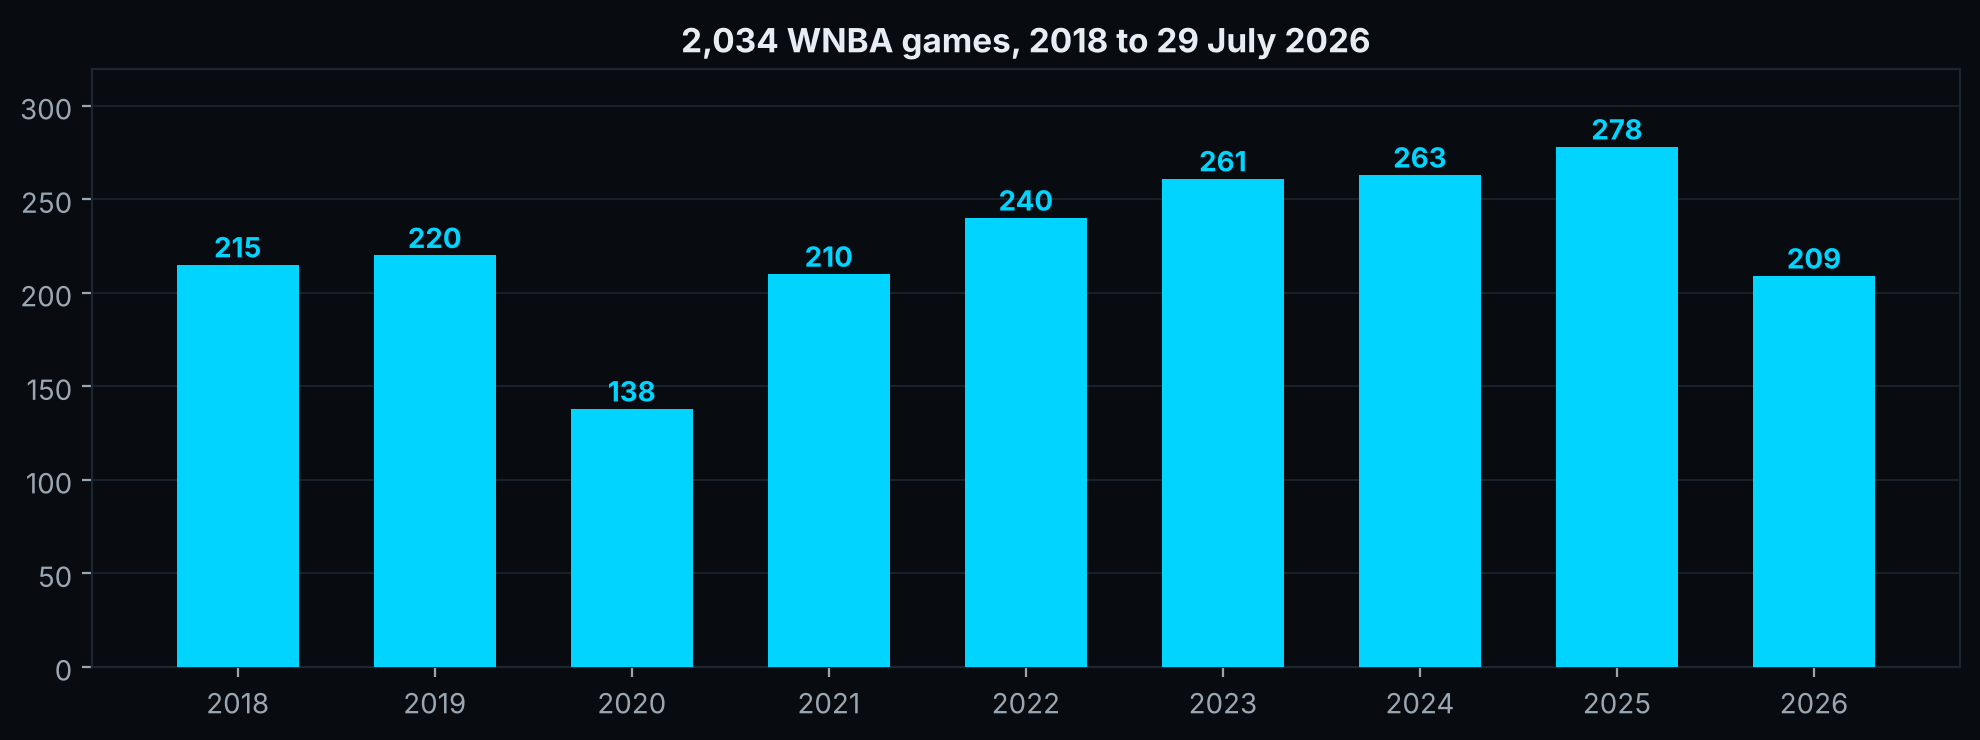

In [4]:
per_season = F["Season"].astype(str).value_counts().sort_index().to_dict()
check("games per season, as listed", per_season == CLAIMS["games_per_season"], " · ".join(f"{k} {v}" for k, v in per_season.items()))
check(f"from {CLAIMS['first_date']} to {CLAIMS['last_date']}", F["Date"].min() == CLAIMS["first_date"] and F["Date"].max() == CLAIMS["last_date"])
teams = sorted(set(F["Away_Team"]) | set(F["Home_Team"]))
check("fifteen franchises, full names", teams == CLAIMS["teams"], f"{len(teams)}")
a, h = F["Away_Score"], F["Home_Score"]
check("Winner, Total_Points and Margin (home minus away) agree with the score on every row; no tie",
      ((h > a) == (F["Winner"] == "Home")).all() and (F["Total_Points"] == a + h).all() and (F["Margin"] == h - a).all() and (a != h).all())
check("every game has a tip-off time (US Eastern, 24-hour clock) and the right weekday",
      S["Time"].str.fullmatch(r"\d{2}:\d{2}").all() and (pd.to_datetime(F["Date"]).dt.strftime("%a") == F["Day"]).all())
per_team = {}
for s, g in F.groupby(F["Season"].astype(str)):
    per_team[s] = pd.concat([g["Away_Team"], g["Home_Team"]]).value_counts().sort_index().to_dict()
diff = [f"{s} {t}" for s, d in CLAIMS["games_per_team_complete_seasons"].items() for t, n in d.items() if per_team[s].get(t) != n]
check("2019, 2021, 2022, 2023, 2024: every franchise has its full number of games (regular season, Cup final, playoffs)",
      not diff, ", ".join(diff[:6]))

fig, ax = plt.subplots(figsize=(10, 3.8))
x = list(per_season)
ax.bar(x, per_season.values(), color=CYAN, width=0.62, zorder=3)
for i, v in enumerate(per_season.values()):
    ax.text(i, v + 4, f"{v}", ha="center", color=CYAN, fontsize=10, fontweight="bold")
ax.set_title(f"{len(F):,} WNBA games, 2018 to 29 July 2026")
ax.set_ylim(0, max(per_season.values()) * 1.15); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 4 · Prices

Every market is complete or empty for a source; every American price has its decimal twin; the margins, the lines
and the favorites hold together. Before 23 June 2026 the American price is the one published and the decimal one is
converted; from 23 June 2026 the source shows decimal prices, so the American one is converted.

In [5]:
def conv(us):
    return np.where(us > 0, 1 + us / 100, 1 + 100 / np.abs(us))

partial = {}
for s in SOURCES:
    for m, fl in MARKETS.items():
        pres = F[[f"{s}_{f}" for f in fl]].notna()
        n = int((pres.any(axis=1) & ~pres.all(axis=1)).sum())
        if n:
            partial[f"{s} {m}"] = n
check("every market is complete (both sides, line and prices) or empty, for every source", not partial, str(partial))

dec_period = F["Date"] >= CLAIMS["decimal_from"]
check(f"{CLAIMS['decimal_games']} games from 23 June 2026, the decimal-price period", int(dec_period.sum()) == CLAIMS["decimal_games"])
bad_before, bad_after = 0, 0
for c in US_COLS:
    us, de = F[c], F[c[:-3] + "_Dec"]
    ok = us.notna()
    before = ok & ~dec_period
    bad_before += int((np.abs(conv(us[before]) - de[before]) > 0.005 + 1e-9).sum())
    back = np.where(de[ok & dec_period] >= 2, np.round((de[ok & dec_period] - 1) * 100), -np.round(100 / (de[ok & dec_period] - 1)))
    bad_after += int((back != us[ok & dec_period]).sum())
check("before 23 June 2026: every decimal price is the American price converted, rounded to 2 decimals", bad_before == 0, f"{bad_before} off")
check("from 23 June 2026: every American price is the decimal price converted, to the whole number", bad_after == 0, f"{bad_after} off")
check("no American price between -100 and +100, none at 10000 or beyond", ((F[US_COLS].abs() >= 100) | F[US_COLS].isna()).all().all()
      and not (F[US_COLS].abs() >= 10000).any().any())

over_bad = {}
for s in SOURCES:
    for m, (x, y) in PAIRS.items():
        a_, b_ = F[f"{s}_{x}"], F[f"{s}_{y}"]
        ov = imp(a_) + imp(b_)
        lo, hi = (1.015, 1.25) if m == "ML" else (1.0, 1.15)
        bad = a_.notna() & ((ov < lo) | (ov > hi) | ((m == "ML") & (a_ > 0) & (b_ > 0)))
        if bad.sum():
            over_bad[f"{s} {m}"] = int(bad.sum())
check("margins: moneyline 1.5% to 25%, never both sides plus money; spread and total 0% to 15%", not over_bad, str(over_bad))
check("the spread lines of the two teams are opposite, for every source",
      all(((F[f"{s}_Spread_Away_Line"] + F[f"{s}_Spread_Home_Line"]).abs().fillna(0) < 1e-9).all() for s in SOURCES))
check("every total line between 120 and 200 points",
      all(F[f"{s}_Total_Line"].dropna().between(120, 200).all() for s in SOURCES))
contra = 0
for s in SOURCES:
    p = no_vig(F[f"{s}_ML_Home_US"], F[f"{s}_ML_Away_US"]); lh = F[f"{s}_Spread_Home_Line"].to_numpy()
    contra += int((((p >= 0.53) & (lh >= 1)) | ((p <= 0.47) & (lh <= -1))).sum())
check("no source whose moneyline and spread name different favorites (53% and one point, as in the README)", contra == 0, f"{contra}")
P = pd.DataFrame({b: no_vig(F[f"{b}_ML_Home_US"], F[f"{b}_ML_Away_US"]) for b in BOOKS})
L = pd.DataFrame({b: F[f"{b}_Spread_Home_Line"] for b in BOOKS})
T = pd.DataFrame({b: F[f"{b}_Total_Line"] for b in BOOKS})
far = 0
for b in BOOKS:
    o_ = [x for x in BOOKS if x != b]
    for M, thr, strict in ((P, 0.15, True), (L, 4.0, False), (T, 6.0, False)):
        dev = (M[b] - M[o_].median(axis=1)).abs()
        enough = M[o_].notna().sum(axis=1) >= 2
        far += int((enough & ((dev > thr) if strict else (dev >= thr))).sum())
check("no closing price far from the other books (15 points of probability, 4 spread points, 6 total points)", far == 0, f"{far}")

PASS  every market is complete (both sides, line and prices) or empty, for every source   [{}]
PASS  84 games from 23 June 2026, the decimal-price period


PASS  before 23 June 2026: every decimal price is the American price converted, rounded to 2 decimals   [0 off]
PASS  from 23 June 2026: every American price is the decimal price converted, to the whole number   [0 off]
PASS  no American price between -100 and +100, none at 10000 or beyond
PASS  margins: moneyline 1.5% to 25%, never both sides plus money; spread and total 0% to 15%   [{}]
PASS  the spread lines of the two teams are opposite, for every source
PASS  every total line between 120 and 200 points
PASS  no source whose moneyline and spread name different favorites (53% and one point, as in the README)   [0]
PASS  no closing price far from the other books (15 points of probability, 4 spread points, 6 total points)   [0]


## 5 · Coverage

Games with a price, source by source and market by market, then the moneyline season by season.

PASS  games with a price, every source and market, as in the README   [Opener 1,970 · Betcris 1,658 · Heritage 2,020 · BetOnline 2,001 · Bovada 2,007 · BetAnything 1,212 · WilliamHill 2,009 · Everygame 2,020]
PASS  moneyline coverage season by season, as in the README
PASS  Betcris has no moneyline on 316 games in a row, from 2021-08-12 to 2022-08-21   [(316, '2021-08-12', '2022-08-21')]
PASS  BetAnything starts in September 2021: spreads and totals on 7 September, the moneyline on 6 October   [{'ML': '2021-10-06', 'Spread': '2021-09-07', 'Total': '2021-09-07'}]
PASS  all seven books have a closing moneyline on 963 games; the median game has 6   [963 · median 6]
PASS  three games without any closing moneyline, as listed   [[['2018-06-30', 'Phoenix Mercury', 'Washington Mystics'], ['2019-07-17', 'Atlanta Dream', 'Chicago Sky'], ['2020-07-26', 'Connecticut Sun', 'Minnesota Lynx']]]


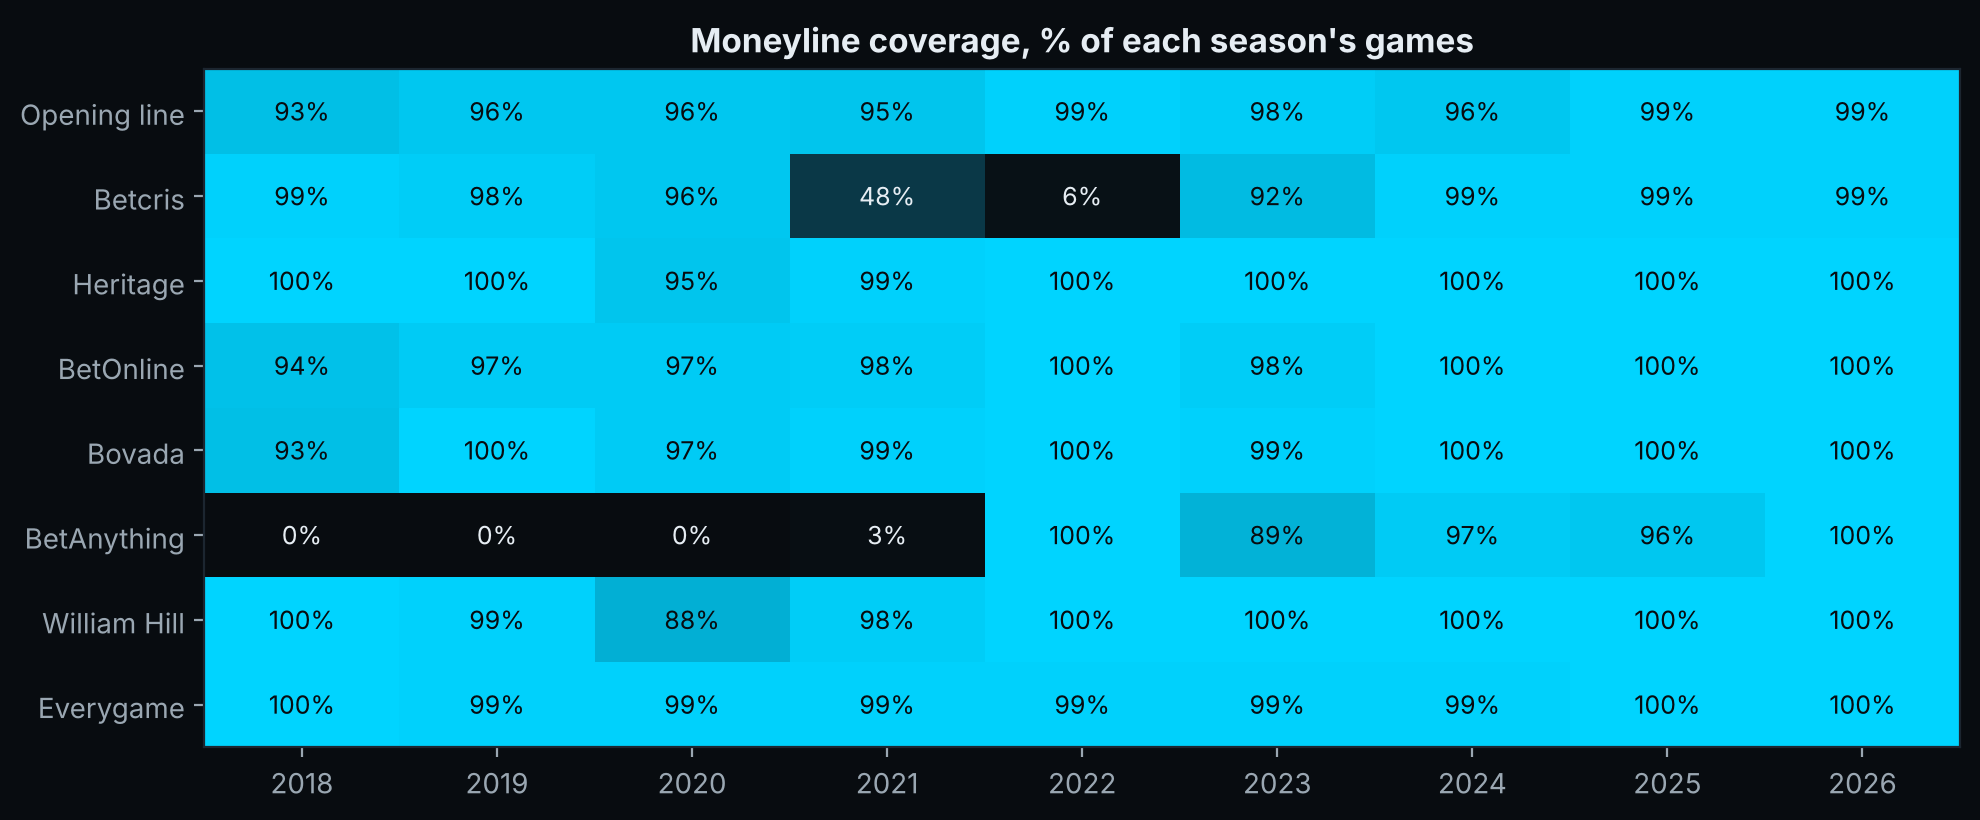

In [6]:
cov = {s: {m: int(F[f"{s}_{c}"].notna().sum()) for m, c in KEY.items()} for s in SOURCES}
check("games with a price, every source and market, as in the README", cov == CLAIMS["coverage_games"],
      " · ".join(f"{s} {cov[s]['ML']:,}" for s in SOURCES))
ml_season = {s: {str(se): int(round(100 * g[f"{s}_ML_Away_US"].notna().mean())) for se, g in F.groupby("Season")} for s in SOURCES}
check("moneyline coverage season by season, as in the README", ml_season == CLAIMS["ml_coverage_by_season_pct"])

has = F["Betcris_ML_Away_US"].notna().to_numpy()
runs, start = [], None
for i, x in enumerate(has):
    if not x and start is None:
        start = i
    if x and start is not None:
        runs.append((i - start, F["Date"][start], F["Date"][i - 1])); start = None
gap = max(runs)
bg = CLAIMS["betcris_gap"]
check(f"Betcris has no moneyline on {bg['games']} games in a row, from {bg['from']} to {bg['to']}",
      gap == (bg["games"], bg["from"], bg["to"]), f"{gap}")
first = {m: F.loc[F[f"BetAnything_{c}"].notna(), "Date"].iloc[0] for m, c in KEY.items()}
check("BetAnything starts in September 2021: spreads and totals on 7 September, the moneyline on 6 October",
      first == CLAIMS["betanything_first"], str(first))
n_close = F[[f"{b}_ML_Away_US" for b in BOOKS]].notna().sum(axis=1)
check(f"all seven books have a closing moneyline on {CLAIMS['games_all_7_books_ml']:,} games; the median game has "
      f"{CLAIMS['median_closing_books_ml']}", int((n_close == 7).sum()) == CLAIMS["games_all_7_books_ml"]
      and n_close.median() == CLAIMS["median_closing_books_ml"], f"{int((n_close == 7).sum())} · median {n_close.median():g}")
none = F.loc[n_close == 0, ["Date", "Away_Team", "Home_Team"]].values.tolist()
check("three games without any closing moneyline, as listed", none == CLAIMS["games_without_closing_ml"], str(none))

cmap = LinearSegmentedColormap.from_list("osd", [BG, "#0b3a4a", CYAN])
M = pd.DataFrame(ml_season).T
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.imshow(M.to_numpy(), cmap=cmap, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(M.shape[1]), M.columns); ax.set_yticks(range(M.shape[0]), [NAME.get(s, s) for s in M.index])
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.iat[i, j]
        ax.text(j, i, f"{v}%", ha="center", va="center", fontsize=9, color=BG if v > 60 else FG)
ax.grid(False); ax.set_title("Moneyline coverage, % of each season's games")
plt.tight_layout(); plt.show()

## 6 · Public betting split

The share of bets on each side of each market, as published with the odds. The two sides add up to 100; a split
recorded 0% / 0% was left empty.

In [7]:
got = {m: int(F[c].notna().sum()) for m, c in (("ML", "ML_Away_Bet%"), ("Spread", "Spread_Away_Bet%"), ("Total", "Total_Over_Bet%"))}
check(f"betting split on {CLAIMS['betting_split_games']['ML']:,} games for the moneyline, "
      f"{CLAIMS['betting_split_games']['Spread']:,} for the spread and the total", got == CLAIMS["betting_split_games"], str(got))
ok = True
for x, y in (("ML_Away_Bet%", "ML_Home_Bet%"), ("Spread_Away_Bet%", "Spread_Home_Bet%"), ("Total_Over_Bet%", "Total_Under_Bet%")):
    ok &= bool((F[x].notna() == F[y].notna()).all()) and bool(((F[x] + F[y] - 100).abs().dropna() <= 1).all())
check("both sides given or both empty, and the two sides add up to 100", ok)

PASS  betting split on 1,879 games for the moneyline, 1,979 for the spread and the total   [{'ML': 1879, 'Spread': 1979, 'Total': 1979}]
PASS  both sides given or both empty, and the two sides add up to 100


## 7 · Are these real market prices?

A real closing line is calibrated: when the market makes the home team a 70% favorite, the home team should win about
70% of the time. The median of the seven books' closing moneylines, margin removed, against what happened.

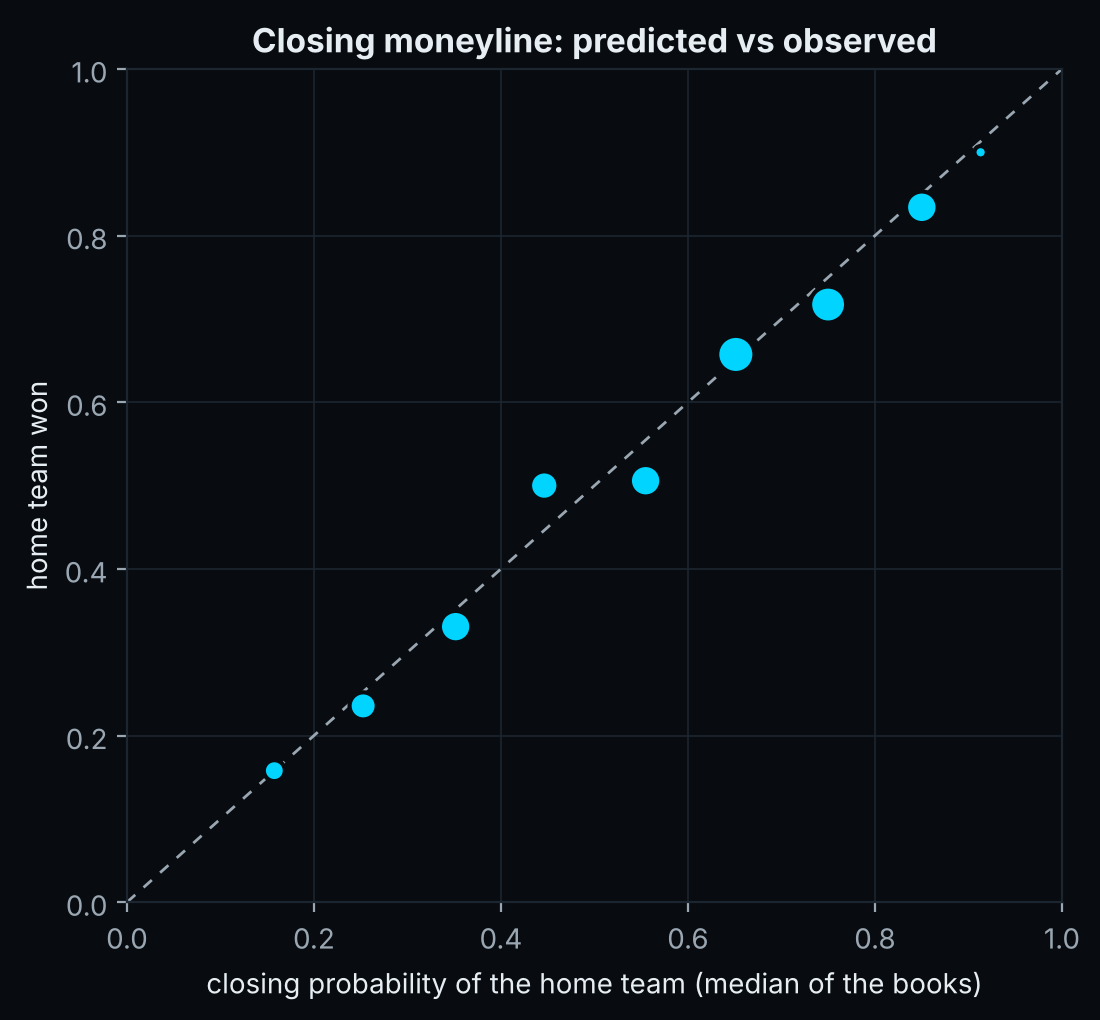

2,031 games · the home team won 54.9% of all games


,p,freq,n
bin,,,
"(0.1, 0.2]",0.158,0.158,114
"(0.2, 0.3]",0.253,0.236,191
"(0.3, 0.4]",0.352,0.331,257
"(0.4, 0.5]",0.446,0.500,210
"(0.5, 0.6]",0.555,0.506,257
"(0.6, 0.7]",0.651,0.657,359
"(0.7, 0.8]",0.750,0.717,336
"(0.8, 0.9]",0.850,0.834,259
"(0.9, 1.0]",0.913,0.900,40


In [8]:
won = (F["Winner"] == "Home").to_numpy()
p = P.median(axis=1).to_numpy()   # NaN when no book has a closing moneyline
ok = ~np.isnan(p)
cal = pd.DataFrame({"p": p[ok], "hit": won[ok]})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.1))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 30]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 2, 12, 200), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("closing probability of the home team (median of the books)"); ax.set_ylabel("home team won")
ax.set_title("Closing moneyline: predicted vs observed")
plt.tight_layout(); plt.show()
print(f"{ok.sum():,} games · the home team won {won.mean():.1%} of all games")
cb.round(3)

## 8 · The games on the listing's images

The images of the listing are drawn from the file. Every number they show, recomputed.

In [9]:
def game(d, a, h):
    g = F[(F["Date"] == d) & (F["Away_Team"] == a) & (F["Home_Team"] == h)]
    assert len(g) == 1, (d, a, h)
    return g.iloc[0]

img1 = {k: [int(game(*k.split("|"))[f"{s}_ML_Home_US"]) for s in ("Opener", "Betcris", "BetOnline", "Bovada", "Heritage")]
        for k in COVERS["cover_1_home_ml"]}
check("image 1: home team moneyline of the 4 games of the 2025 Finals, opening line, Betcris, BetOnline, Bovada, Heritage",
      img1 == COVERS["cover_1_home_ml"])
c2 = COVERS["cover_2_game"]; r = game(c2["date"], c2["away"], c2["home"])
img2 = {s: [int(r[f"{s}_ML_Away_US"]), int(r[f"{s}_ML_Home_US"]), float(r[f"{s}_Spread_Home_Line"]), float(r[f"{s}_Total_Line"])] for s in SOURCES}
check("image 2: 2025 Finals Game 4, Aces at Mercury, 97-86: every source's moneylines, Mercury spread and total; "
      "55% of moneyline bets on the Aces, 78% on the over",
      img2 == c2["rows"] and [int(r["Away_Score"]), int(r["Home_Score"])] == c2["score"]
      and [int(r["ML_Away_Bet%"]), int(r["Total_Over_Bet%"])] == c2["bets"])
c3 = COVERS["cover_3_spread_moves"]
img3 = {}
for _, g in F[F["Date"] == c3["date"]].iterrows():
    img3[f"{g['Away_Team']}|{g['Home_Team']}"] = [float(g[f"{s}_Spread_Home_Line"]) for s in ("Opener", "Betcris", "Bovada", "Heritage")] + [int(g["Margin"])]
check("image 3: every game of 28 July 2026, home spread at the opening line and at Betcris, Bovada and Heritage, final margin",
      img3 == c3["rows"])
c4 = COVERS["cover_4_public_split"]
img4 = {k: [int(game(c4["date"], *k.split("|"))[c]) for c in ("ML_Away_Bet%", "ML_Home_Bet%", "Spread_Away_Bet%", "Spread_Home_Bet%",
                                                              "Total_Over_Bet%", "Away_Score", "Home_Score")] for k in c4["rows"]}
check("image 4: betting split and final score of 5 games of 22 July 2026", img4 == c4["rows"])
img5 = {s: [round(100 * F[f"{s}_{c}"].notna().mean(), 1) for c in KEY.values()] for s in SOURCES}
check("image 5: share of games with a price, every source and market", img5 == COVERS["cover_5_coverage_pct"])
t6 = COVERS["cover_6_tiles"]
check(f"image 6: {t6['games']:,} games, {t6['seasons']} seasons, {t6['sources']} sources, {t6['prices']:,} prices, {t6['columns']} columns",
      [len(F), F["Season"].nunique(), len(SOURCES), int(F[US_COLS].notna().sum().sum()), F.shape[1]]
      == [t6["games"], t6["seasons"], t6["sources"], t6["prices"], t6["columns"]])

PASS  image 1: home team moneyline of the 4 games of the 2025 Finals, opening line, Betcris, BetOnline, Bovada, Heritage
PASS  image 2: 2025 Finals Game 4, Aces at Mercury, 97-86: every source's moneylines, Mercury spread and total; 55% of moneyline bets on the Aces, 78% on the over
PASS  image 3: every game of 28 July 2026, home spread at the opening line and at Betcris, Bovada and Heritage, final margin


PASS  image 4: betting split and final score of 5 games of 22 July 2026
PASS  image 5: share of games with a price, every source and market
PASS  image 6: 2,034 games, 9 seasons, 8 sources, 89,964 prices, 137 columns


## 9 · Said plainly, checked

The limits the listing states up front, recomputed.

In [10]:
check("the 2026 season stops on 29 July 2026", F.loc[F["Season"] == 2026, "Date"].max() == "2026-07-29")
check("one opening line (Opener), no opening price per book: the seven books carry closing prices only",
      not any("Open" in c for c in F.columns if not c.startswith("Opener_")))
check("no BetAnything price before September 2021",
      F.loc[F["Date"] < "2021-09-01", [c for c in F.columns if c.startswith("BetAnything_")]].isna().all().all())
check("no preseason or All-Star rows: every row is a game between two of the fifteen franchises",
      set(F["Away_Team"]) | set(F["Home_Team"]) <= set(CLAIMS["teams"]) and (F["Away_Team"] != F["Home_Team"]).all())

PASS  the 2026 season stops on 29 July 2026
PASS  one opening line (Opener), no opening price per book: the seven books carry closing prices only
PASS  no BetAnything price before September 2021
PASS  no preseason or All-Star rows: every row is a game between two of the fifteen franchises


## 10 · Summary

In [11]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} / {len(summary)} claims verified")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

39 / 39 claims verified


Result,Claim,Detail
PASS,"2,034 games, one row each","2,034 rows"
PASS,"137 columns: 17 for the game, 15 per source for 8 sources, in the documented order",137 columns
PASS,"UTF-8 with BOM, semicolon-separated, Windows line ends",
PASS,no BookMaker or Ozoon column (removed in this edition),
PASS,"89,964 prices, each in American and decimal odds","89,964"
PASS,"games per season, as listed",2018 215 · 2019 220 · 2020 138 · 2021 210 · 2022 240 · 2023 261 · 2024 263 · 2025 278 · 2026 209
PASS,from 2018-05-18 to 2026-07-29,
PASS,"fifteen franchises, full names",15
PASS,"Winner, Total_Points and Margin (home minus away) agree with the score on every row; no tie",
PASS,"every game has a tip-off time (US Eastern, 24-hour clock) and the right weekday",


---

Everything above ran on the file a buyer downloads. The README in the ZIP holds the full column dictionary, the coverage
of every source season by season, how each price was checked, what changed since the first edition and every known
limitation.

👉 🏀 **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/rnlhra?utm_source=github&utm_medium=notebook&utm_campaign=wnba_oc&utm_content=notebook_bottom)** · also on [Whop](https://whop.com/oliviersportsdata/wnba-opening-closing-odds-7-books-opening-line-2018-2026/?utm_source=github&utm_medium=notebook&utm_campaign=wnba_oc&utm_content=whop_bottom) 👈

A question before buying: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*